# Luthera Family Plots



In [1]:
import pandas as pd
import numpy as np
import h5py as h5

import datetime as datetime

import matplotlib.pyplot as plt

In [2]:
path = '../../asteroid_data/luthera_family.h5'
luth_fam = pd.read_hdf(path)

In [3]:
luth_fam['irad'] = np.arcsin(luth_fam['sineI_P'])
luth_fam['ideg'] = np.degrees(luth_fam['irad'])

p_v = 0.0387

luth_fam['diam']= ((1329 * 10**(-luth_fam['abs_mag']/5)) * (p_v ** (-0.5)))
print(luth_fam.sort_values('diam').head())

luth_fam.describe()

      ast_name  abs_mag       a_P       e_P   sineI_P family_id      irad   
715  2008RH174    17.93  3.187963  0.112143  0.314189      1303  0.319602  \
844  2012DU123    17.84  3.203647  0.139780  0.336021      1303  0.342689   
767  2009WM290    17.84  3.189859  0.120059  0.321106      1303  0.326897   
792   2010PT21    17.80  3.190359  0.143706  0.336899      1303  0.343621   
869  2013AK202    17.76  3.186562  0.127768  0.327680      1303  0.333847   

          ideg      diam  
715  18.311861  1.752546  
844  19.634636  1.826710  
767  18.729824  1.826710  
792  19.688057  1.860671  
869  19.128021  1.895263  


,abs_mag,a_P,e_P,sineI_P,irad,ideg,diam
count,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000
mean,16.175513,3.208147,0.123992,0.323863,0.329816,18.897052,4.478502
std,0.987079,0.014558,0.008572,0.005743,0.006072,0.347884,3.757710
min,9.480000,3.172780,0.106420,0.312013,0.317311,18.180585,1.752546
25%,15.620000,3.196843,0.117742,0.320017,0.325747,18.663923,2.829238
50%,16.390000,3.207515,0.123103,0.323137,0.329043,18.852774,3.561800
75%,16.890000,3.219394,0.129976,0.327705,0.333874,19.129568,5.077729
max,17.930000,3.238196,0.144674,0.340954,0.347932,19.935008,85.836005


In [135]:
# MMR values in AU
mmrs_luthera = {'8J:3S:-1':[3.17447,0.9990,1.002], '5J:2S: 2':[3.18,1.0002,0.9995], '5J: 3S: 3':[3.208,0.9995, 1.002]}

# add the MMR lines in a plot with an semi-major axis (a) x axis.
def plot_mmrs(ax, mmr_list, y_min, y_max):
    for mmr_nme, sma in mmrs_luthera.items():
        ax.vlines(sma[0], y_min, y_max*1.001)
        ax.text(sma[0]*sma[1], y_max * sma[2], mmr_nme)


mars_a = 1.666
mars_p = 1.381

jupiter_a = 5.367
jupiter_p = 5.035
jupiter_sm = 5.204

a_range = np.linspace(1.8, 3.9, 1000)
# We want the e for jupiter_p for an a
#d_a = a(1-e)
jupiter_crossing_e = (jupiter_p/a_range)-1
jupiter_q = np.vstack([a_range, jupiter_crossing_e])

mars_crossing_e = 1-(mars_a/a_range)
mars_Q = np.vstack([a_range, mars_crossing_e])

plot_values = np.where((jupiter_q[0,:]>=3.17) & (jupiter_q[0,:]<=3.24))[0]

def plot_crossing_e(ax,x_min, x_max):
    plot_values = np.where((jupiter_q[0,:]>=x_min) & (jupiter_q[0,:]<=x_max))[0]
    ax.plot(mars_Q[:,np.array(plot_values)][0],mars_Q[:,np.array(plot_values)][1])
    ax.plot(jupiter_q[:,np.array(plot_values)][0],jupiter_q[:,np.array(plot_values)][1])


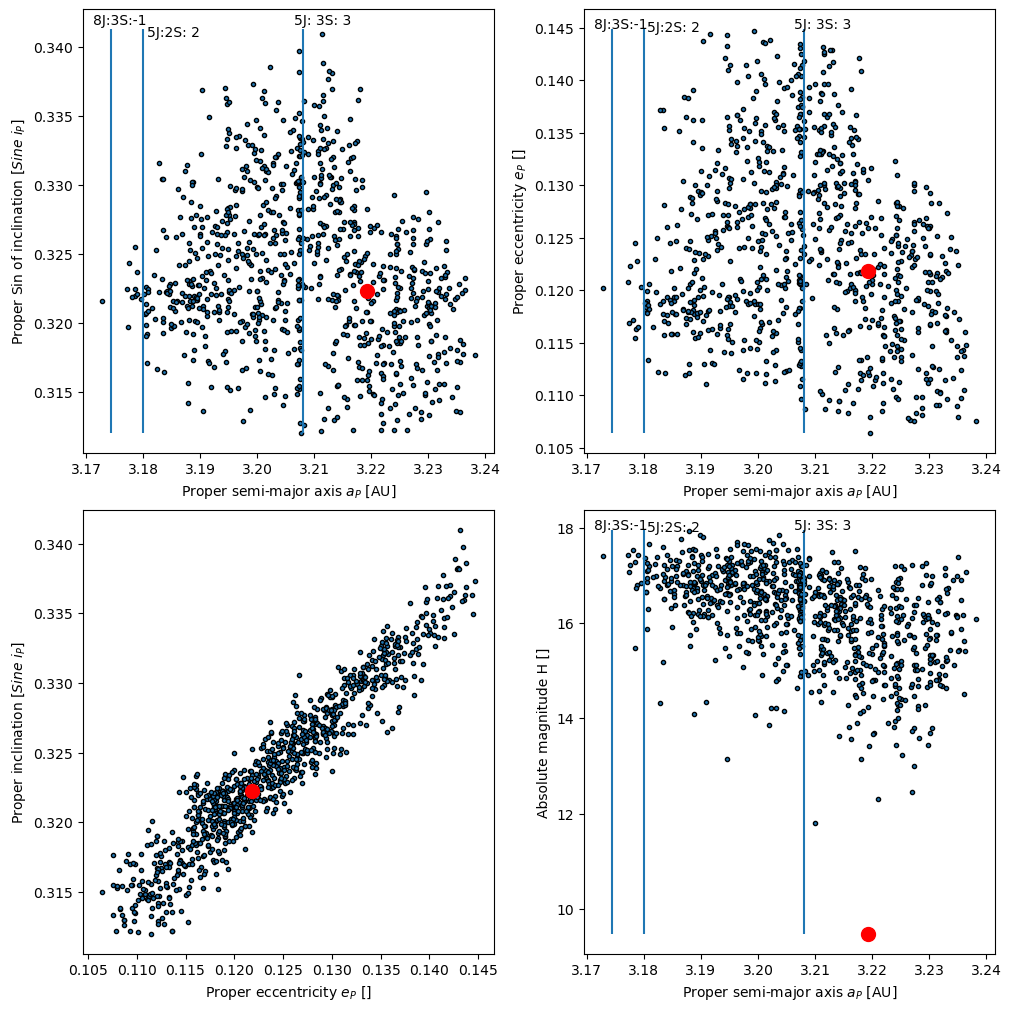

In [137]:
fig = plt.figure(figsize=(10, 10), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=2)

ax1 = fig.add_subplot(spec[0, 0])
ax1.scatter(data=luth_fam, x='a_P',y='sineI_P', edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','sineI_P']].values
ax1.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("Proper Sin of inclination [$Sine ~i_P$]")
plot_mmrs(ax1, mmrs_luthera, luth_fam.sineI_P.min(), luth_fam.sineI_P.max())

ax2 = fig.add_subplot(spec[0, 1])
ax2.scatter(data=luth_fam, x='a_P',y='e_P', edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','e_P']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Proper eccentricity $e_P$ []")
plot_mmrs(ax2, mmrs_luthera, luth_fam.e_P.min(), luth_fam.e_P.max())

ax3 = fig.add_subplot(spec[1, 0])
plt.scatter(data=luth_fam, x='e_P',y='sineI_P' , edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['e_P','sineI_P']].values
ax3.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax3.set_xlabel("Proper eccentricity $e_P$ []")
ax3.set_ylabel("Proper inclination [$Sine ~i_P$]")

ax4 = fig.add_subplot(spec[1, 1])
ax4.scatter(data=luth_fam, x='a_P',y='abs_mag' , edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','abs_mag']].values
ax4.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax4.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax4.set_ylabel("Absolute magnitude H []")
plot_mmrs(ax4, mmrs_luthera, luth_fam.abs_mag.min(), luth_fam.abs_mag.max())

plt.savefig(f"../../dissertation/luthera_proper_plts.png", dpi=300)
plt.show()


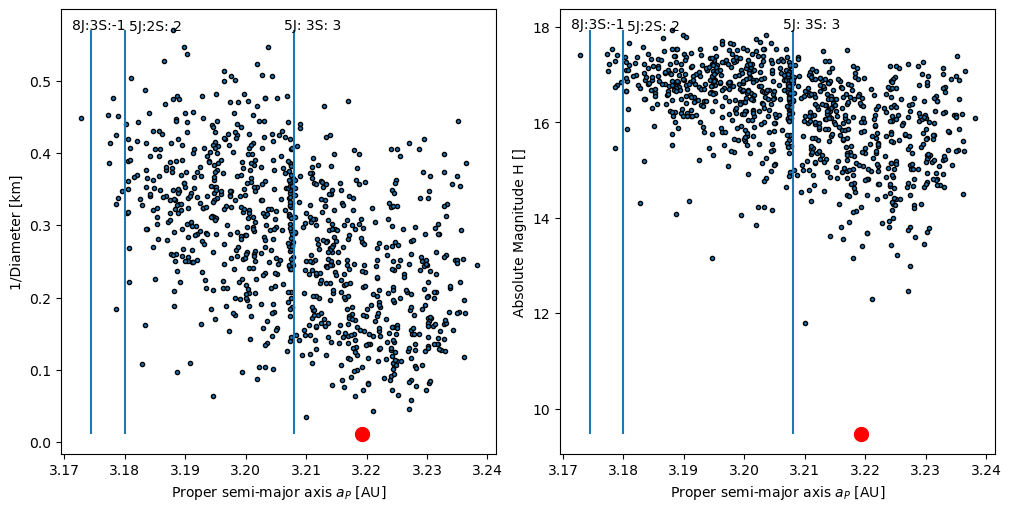

In [142]:
fig = plt.figure(figsize=(10, 5), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])

over_D = 1/luth_fam.diam

ax1.scatter(x=luth_fam.a_P,y=over_D, edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','diam']].values
ax1.plot(luth_ie[0][0],1/luth_ie[0][1], 'ro', markersize=10)
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("1/Diameter [km]")
plot_mmrs(ax1, mmrs_luthera, over_D.min(), over_D.max())

ax2 = fig.add_subplot(spec[0, 1])
ax2.scatter(x=luth_fam.a_P,y=luth_fam.abs_mag , edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','abs_mag']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Absolute Magnitude H []")
plot_mmrs(ax2, mmrs_luthera, luth_fam.abs_mag.min(), luth_fam.abs_mag.max())

plt.show()


In [6]:
brights = luth_fam[luth_fam['abs_mag']<13]

brights

,ast_name,abs_mag,a_P,e_P,sineI_P,family_id,irad,ideg,diam
0,1303,9.48,3.219248,0.121842,0.322276,1303,0.328133,18.800624,85.836005
1,11911,11.80,3.210027,0.132169,0.330567,1303,0.336904,19.303194,29.489642
3,17840,12.46,3.227073,0.122213,0.322861,1303,0.328751,18.836035,21.760531
5,33292,12.99,3.227360,0.129485,0.326713,1303,0.332824,19.069389,17.047845
15,65871,12.31,3.221049,0.122196,0.322120,1303,0.327968,18.791182,23.316830


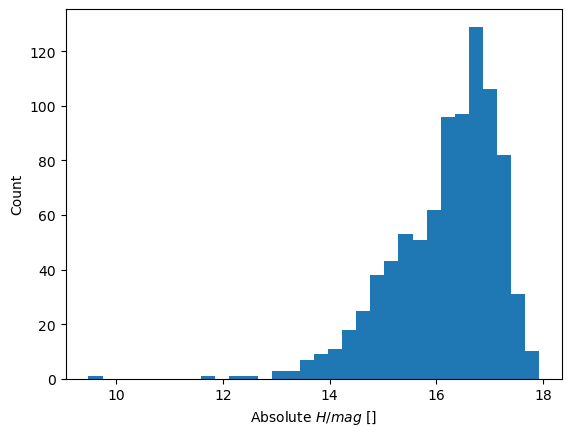

In [11]:
plt.hist(data=luth_fam, x='abs_mag' , bins='auto')
plt.ylabel("Count")
plt.xlabel("Absolute $H / mag$ []")
plt.show()

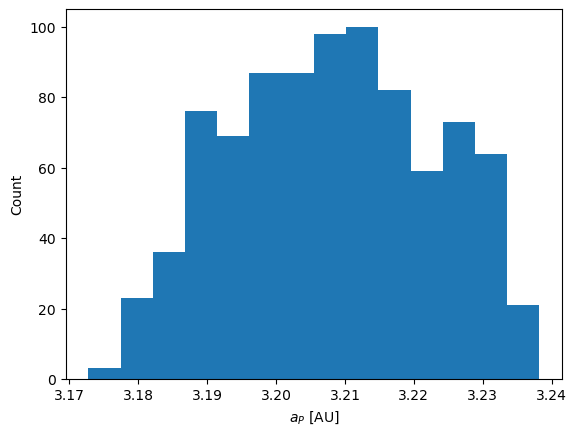

In [8]:
plt.hist(data=luth_fam, x='a_P', bins='auto')
plt.ylabel("Count")
plt.xlabel("$a_P$ [AU]")
plt.show()

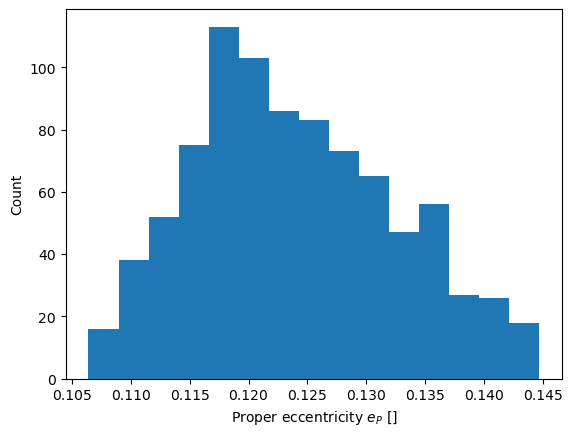

In [9]:
plt.hist(data=luth_fam, x='e_P', bins='auto')
plt.ylabel("Count")
plt.xlabel("Proper eccentricity $e_P$ []")
plt.show()

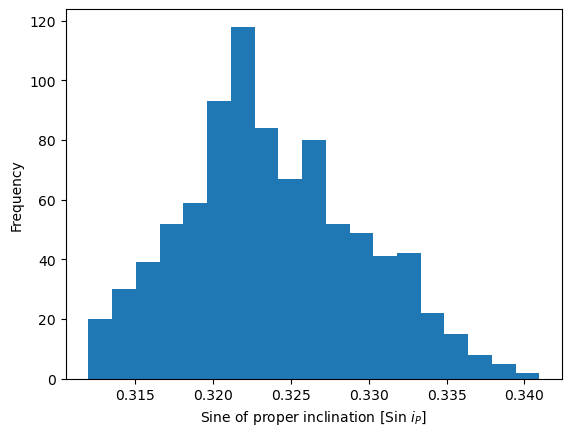

In [10]:
plt.hist(data=luth_fam, x='sineI_P', bins='auto')
plt.ylabel("Frequency")
plt.xlabel("Sine of proper inclination [Sin $i_P$]")
plt.show()

In [ ]:
mvc3_1g = 2.4 * 24 * 3600
mc3_1g = (19/24) * 24 * 3600
cluster_p = 700
tot_simulations = 19050

print(f"mvc3_1g Expected time with {cluster_p: 5} cores:{datetime.timedelta(seconds=mvc3_1g * (tot_simulations/cluster_p))}")

print(f"mvc3_1g Expected time with {cluster_p*10: 5} cores: {datetime.timedelta(seconds=mvc3_1g *(tot_simulations/(cluster_p*10)))}")

print(f"mc3_1g  Expected time with {cluster_p: 5} cores:{datetime.timedelta(seconds=mc3_1g *(tot_simulations/cluster_p))}")

print(f"mc3_1g  Expected time with {cluster_p*10: 5} cores: {datetime.timedelta(seconds=mc3_1g *(tot_simulations/(cluster_p*10)))}")


In [ ]:
month = 30 * 24 * 3600

print(f"Month of sims each 1.4 days {cluster_p*(month/mvc3_1g)}")


## Plot a asteroid family context scatter 
this plot includes: 
* Jupiter and Mars crossing lines
* MMR resonance lines
* Secular resonance lines


In [ ]:



ax2 = fig.add_subplot(spec[0, 1])
ax2.scatter(data=luth_fam, x='a_P',y='e_P', edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','e_P']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Proper eccentricity $e_P$ []")
plot_mmrs(ax2, mmrs_luthera, luth_fam.e_P.min(), luth_fam.e_P.max())
